# Reproduce Group Trajectories Plot

This notebook contains the minimal code necessary to process the simulation data and reproduce the group trajectory phase plots.

## 1. Imports and Setup
Load the necessary libraries for data manipulation, mathematical operations, clustering, and plotting.

In [26]:
import os
import numpy as np
import pandas as pd
pd.set_option('future.no_silent_downcasting', True)
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns
import numpy.ma as ma
from scipy.stats import binned_statistic_2d
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Polygon
from sklearn.cluster import KMeans
from scipy.special import softmax
from dotenv import load_dotenv

## 2. Data Loading
Load the `merged_agent_stats.parquet` dataset using paths from environment variables.

In [2]:
# Load environment variables from .env if present
load_dotenv()

# Construct the path using WANDB_DIR
wandb_dir = os.environ.get("WANDB_DIR", "./")
data_path = os.path.join(wandb_dir, "data", "lck2wafo_dment0yi", "merged_agent_stats.parquet")

print(f"Loading data from {data_path}...")
try:
    # Load the parquet file (much faster for large datasets)
    df = pd.read_parquet(data_path)
except FileNotFoundError:
    # Fallback to the CSV if parquet isn't available for some reason
    csv_path = data_path.replace(".parquet", ".csv.gz")
    print(f"Parquet not found. Falling back to CSV: {csv_path}")
    df = pd.read_csv(csv_path)

print(f"Dataset shape: {df.shape}")

Loading data from /groups/romanczuk/Chirkov_wandb/ssga/data/lck2wafo_dment0yi/merged_agent_stats.parquet...
Dataset shape: (6000000, 13)


In [3]:
df[df['close_target_index'] == 1].head(10)

,group_id,agent_id,age,cumulative_fitness,current_fitness,avg_fitness,gene_priv,gene_soc,gene_none,gene_eve,run_id,close_target_index,step
3000000,0.0,0.0,1000.0,-16.126007,-0.001305,-0.016126,0.367425,-0.240265,0.075739,-0.644270,dment0yi,1,999
3000001,0.0,1.0,1000.0,-21.384817,-0.041248,-0.021385,0.987102,-0.111018,0.310793,0.440495,dment0yi,1,999
3000002,0.0,2.0,1000.0,-12.309797,0.008686,-0.012310,0.150497,0.472290,-0.321096,-0.453458,dment0yi,1,999
3000003,0.0,3.0,1000.0,-16.137848,-0.001279,-0.016138,0.067888,-0.256189,-0.435010,0.634646,dment0yi,1,999
3000004,0.0,4.0,1000.0,-19.268465,0.008669,-0.019268,0.249322,-0.082900,-0.556916,0.113567,dment0yi,1,999
3000005,0.0,5.0,1000.0,-26.056572,-0.001205,-0.026057,0.939226,0.018278,-0.577366,0.448574,dment0yi,1,999
3000006,0.0,6.0,1000.0,-11.703280,0.008559,-0.011703,-0.298317,0.133826,-0.414881,0.080136,dment0yi,1,999
3000007,0.0,7.0,1000.0,-21.220350,0.008736,-0.021220,0.325816,-0.826465,-0.268063,0.267243,dment0yi,1,999
3000008,0.0,8.0,1000.0,-11.937002,-0.041325,-0.011937,0.134198,0.384879,-0.037048,-0.165342,dment0yi,1,999
3000009,0.0,9.0,1000.0,-10.940384,0.008622,-0.010940,0.038964,-1.384284,0.209352,0.995598,dment0yi,1,999


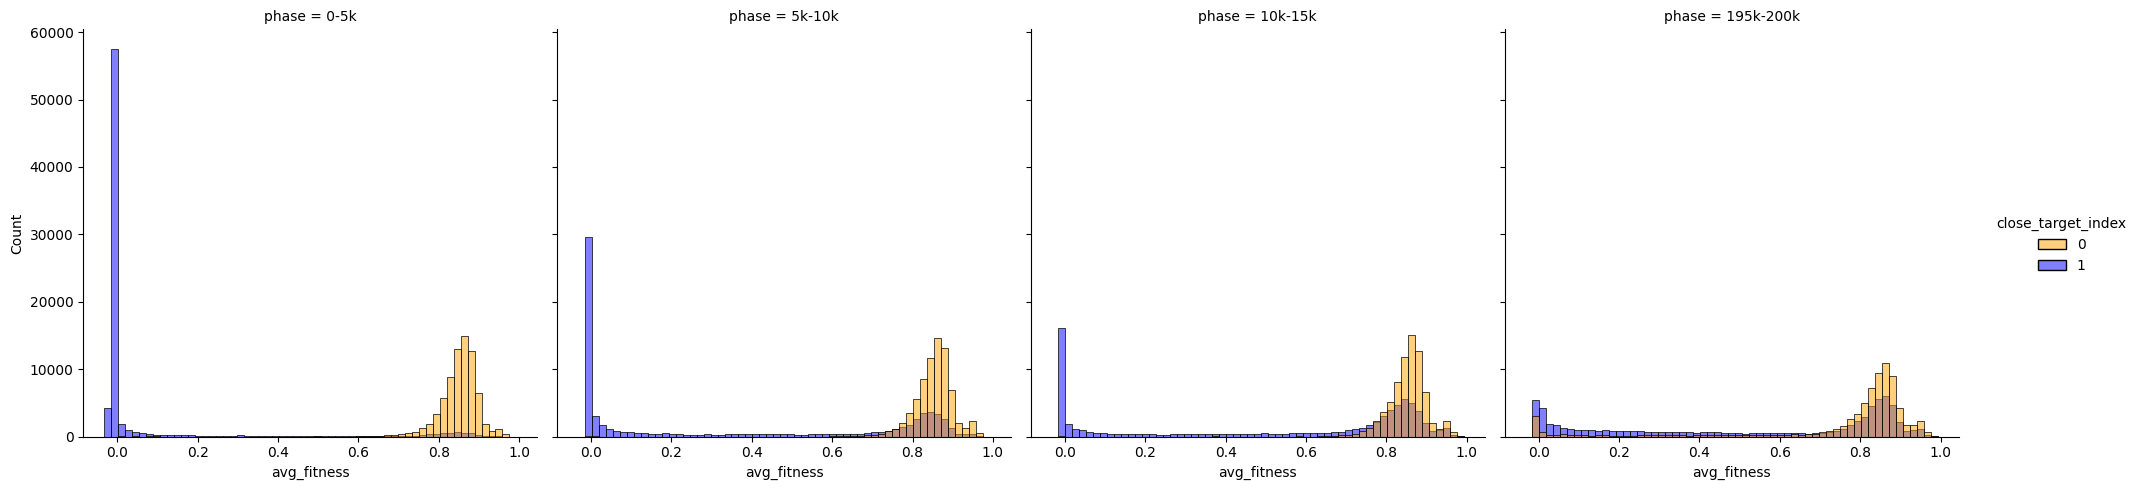

In [4]:
import pandas as pd
pd.set_option('future.no_silent_downcasting', True)
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define all bins, including the gap you want to skip
bins = [0, 5000, 10000, 15000, 195000, 200000] # 20000, 25000,

# 2. Provide labels for every bin, assigning a specific name to the gap
labels = [
    '0-5k', 
    '5k-10k', 
    '10k-15k', 
    # '15k-20k', 
    # '20k-25k', 
    'GAP',       # <--- The 25k to 195k range
    '195k-200k'
]

df['phase'] = pd.cut(
    df['step'], 
    bins=bins, 
    labels=labels,
    include_lowest=True
)

# 3. Create a new dataframe that filters out the gap
df_filtered = df[df['phase'] != 'GAP'].copy()

# 4. emove the unused 'GAP' category entirely
df_filtered['phase'] = df_filtered['phase'].cat.remove_unused_categories()

# 5. Plot using the filtered dataframe
sns.displot(
    data=df_filtered, 
    x='avg_fitness', 
    hue='close_target_index', 
    col='phase', 
    palette={0: 'orange', 1: 'blue'},
    height=5, 
    aspect=1
)

plt.show()

## 3. Data Preparation
Filter for close_target_index=1, compute success metric (if any agent reached > 0.8 fitness), convert gene expression to probabilities, and aggregate to group-level step data.

In [12]:
# Filter for the requested condition
# df_flow = df[df['close_target_index'] == 1].copy()
df_flow = df.copy()

# Determine success for each group AT EACH STEP
# If any agent in the group reached current_fitness > 0.8 at this specific step
group_success = df_flow.groupby(['run_id', 'group_id', 'step'])['current_fitness'].max() > 0.85
group_success.name = 'success'
df_flow = df_flow.merge(group_success, on=['run_id', 'group_id', 'step'])

# 1. Compute softmax probabilities from the raw gene values
genes_cols = ['gene_priv', 'gene_soc', 'gene_none']
probs = softmax(df_flow[genes_cols].values, axis=1)

# Assign probabilities back to the dataframe
df_flow['prob_priv'] = probs[:, 0]
df_flow['prob_soc'] = probs[:, 1]
df_flow['prob_none'] = probs[:, 2]

# 2. Aggregate to group-level step data
# We include 'success' so it's available for splitting the flow fields
group_cols = ['run_id', 'group_id', 'step', 'success']
df_group_steps = df_flow.groupby(group_cols)[['prob_priv', 'prob_soc', 'prob_none', 'gene_eve']].mean().reset_index()

# Ensure chronological ordering
df_group_steps = df_group_steps.sort_values(['run_id', 'group_id', 'step'])

## 4. Trajectory and Gradient Calculations
Map the ternary probabilities (Private, Social, None) into a 2D Cartesian triangle space, and compute the temporal gradients (how the probabilities shift over time).

In [13]:
df_gs = df_group_steps.copy()

# Define the height of the equilateral triangle
H = np.sqrt(3) / 2

# Map ternary coordinates to 2D Cartesian coordinates (mx, my)
df_gs['mx'] = df_gs['prob_none'] + 0.5 * df_gs['prob_soc']
df_gs['my'] = H * df_gs['prob_soc']

# Sort chronologically to accurately compute differences
df_gs = df_gs.sort_values(['run_id', 'group_id', 'step'])

# Calculate the difference (gradient) between consecutive steps for each group
df_gs['dmx'] = df_gs.groupby(['run_id', 'group_id'])['mx'].diff()
df_gs['dmy'] = df_gs.groupby(['run_id', 'group_id'])['my'].diff()

# Drop rows with NaN (first step of each group)
df_gs = df_gs.dropna(subset=['dmx', 'dmy'])

# Normalize step units
df_gs['step'] -= 999
df_gs['step'] /= 1000

# Define time phases: Early (0-5k), Mid (5-12k), Late (12-200k)
max_step = df_gs['step'].max()
time_bins = [0, 5, 12, 200]
time_labels = ['Early', 'Mid', 'Late']

# Our two 'conditions' (clusters) are now True (Success) and False (Failure)
clusters = [True, False]
df_gs.shape

(398000, 12)

## 5. Visualization: Flow Fields by Success
Generate stream plots of the group behavior flow over the three time phases, split into Successful groups (top row) and Failed groups (bottom row).

Overlaying trajectories and rendering plot...


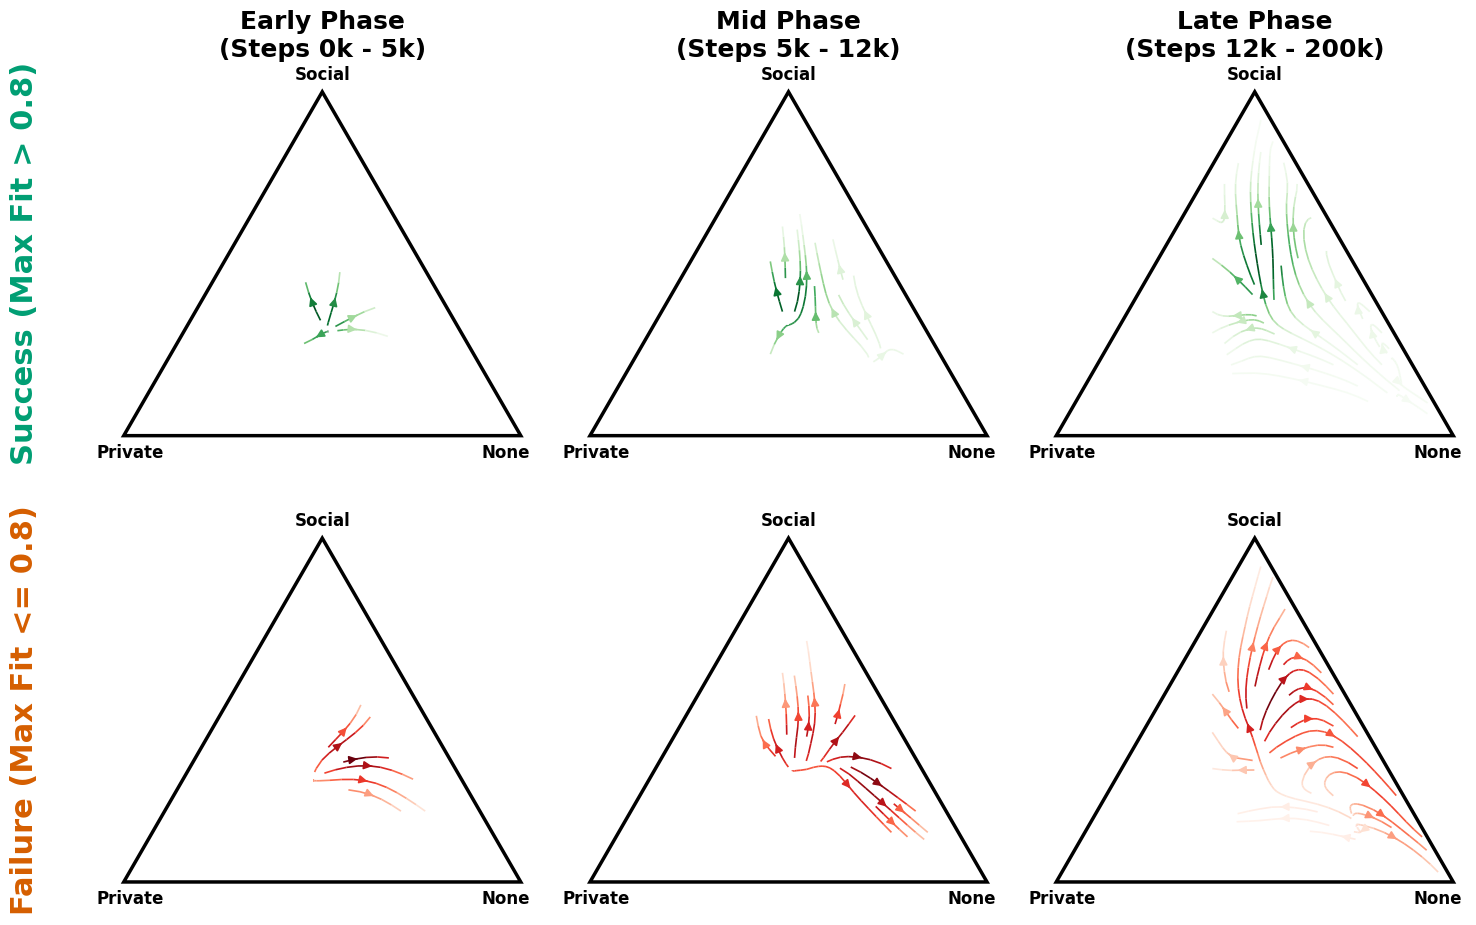

In [14]:
print("Overlaying trajectories and rendering plot...")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
plt.rcParams.update({'font.size': 12})

# Define the 2D grid resolution for the stream plot
grid_res = 35
x_bins = np.linspace(-0.05, 1.05, grid_res)
y_bins = np.linspace(-0.05, H + 0.05, grid_res)
X, Y = np.meshgrid(x_bins[:-1] + np.diff(x_bins)/2, y_bins[:-1] + np.diff(y_bins)/2)

# Colormaps and title colors for Success vs Failure
colors_cluster = {True: 'Greens', False: 'Reds'}
title_colors = {True: '#009E73', False: '#D55E00'}

for row, cluster_val in enumerate(clusters):
    # Filter for Success or Failure
    cluster_data = df_gs[df_gs['success'] == cluster_val]
    
    for col, (t_start, t_end) in enumerate(zip(time_bins[:-1], time_bins[1:])):
        ax = axes[row, col]
        
        # Filter data for the current time phase window
        window_data = cluster_data[(cluster_data['step'] >= t_start) & (cluster_data['step'] < t_end)]
        
        # Draw the bounding equilateral triangle
        triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
        ax.add_patch(triangle)
        
        # Only draw streams if we have enough data points in this window
        if len(window_data) >= 50:
            
            U, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='mean', bins=[x_bins, y_bins])
            V, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmy'], statistic='mean', bins=[x_bins, y_bins])
            Counts, _, _, _ = binned_statistic_2d(window_data['mx'], window_data['my'], window_data['dmx'], statistic='count', bins=[x_bins, y_bins])
            
            U, V, Counts = U.T, V.T, Counts.T
            
            U_smooth = gaussian_filter(np.nan_to_num(U, 0), sigma=1.0)
            V_smooth = gaussian_filter(np.nan_to_num(V, 0), sigma=1.0)
            
            mask = Counts < 5
            U_masked = ma.array(U_smooth, mask=mask)
            V_masked = ma.array(V_smooth, mask=mask)
            
            density = gaussian_filter(Counts, sigma=1.5)
            density_masked = ma.array(density, mask=mask)
            
            try:
                ax.streamplot(X, Y, U_masked, V_masked, color=density_masked, cmap=colors_cluster[cluster_val], 
                              linewidth=1.2, density=1.2, arrowsize=1.2, zorder=2)
            except ValueError:
                pass
        
        ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=12, weight='bold')
        ax.text(0.1, -0.02, "Private", ha='right', va='top', fontsize=12, weight='bold')
        ax.text(0.9, -0.02, "None", ha='left', va='top', fontsize=12, weight='bold')
        
        ax.axis('off')
        ax.set_aspect('equal')
        
        # Top row: Add time phase titles
        if row == 0:
            ax.set_title(f"{time_labels[col]} Phase\n(Steps {int(t_start)}k - {int(t_end)}k)", fontsize=18, weight='bold', pad=15)
    
    # Left column: Add condition labels (Success / Failure)
    cluster_name = 'Success (Max Fit > 0.8)' if cluster_val else 'Failure (Max Fit <= 0.8)'
    axes[row, 0].text(-0.25, H/2, cluster_name, rotation=90, va='center', ha='center', 
                      fontsize=22, weight='bold', color=title_colors[cluster_val])

plt.tight_layout()
plt.subplots_adjust(left=0.08, top=0.90, hspace=0.1, wspace=0.1)
plt.savefig('success_failure_trajectories.png', dpi=300)
plt.show()

## 6. Robust State Identification & Transitions
In this section, we apply a robust state identification pipeline: calculate fitness fraction, apply a 2-step rolling average, assign local states (Success >= 2/3, else Failure), and filter for blocks stable for at least 10 generations. Unstable blocks are marked as 'Mix'.

In [80]:
print("Running robust state identification...")
smoothing_block_size = 1

# df_flow_all = df[df['step'] < 99000].copy()
df_flow_all = df.copy()

# 1. Raw Metric: fraction of agents tracking the target per group per step
df_flow_all['is_fit'] = df_flow_all['current_fitness'] > 0.7
frac_success = df_flow_all.groupby(['run_id', 'group_id', 'step'])['is_fit'].mean().reset_index()
frac_success = frac_success.sort_values(['run_id', 'group_id', 'step'])

# 2. Smoothing: 2-step rolling average
frac_success['smoothed_frac'] = frac_success.groupby(['run_id', 'group_id'])['is_fit'].transform(lambda x: x.rolling(window=3, min_periods=1).mean())

# 3. Local State: Success if >= 2/3, else Failure
# Using np.where to assign states quickly
threshold = 0.5 # 2/3
frac_success['local_state'] = np.where(frac_success['smoothed_frac'] >= (threshold), 'Success', 'Failure')

# 4. Stability Filter: >= smoothing_block_size generations
def apply_stability_filter(df_group):
    # Identify contiguous blocks
    blocks = (df_group['local_state'] != df_group['local_state'].shift()).cumsum()
    df_group['block_id'] = blocks

    # Calculate length of each block
    block_lengths = df_group.groupby('block_id')['step'].transform('count')

    # Assign final stable state
    df_group['stable_state'] = np.where(block_lengths >= smoothing_block_size, df_group['local_state'], 'Mix')
    return df_group

df_success = frac_success.groupby(['run_id', 'group_id'], group_keys=False).apply(apply_stability_filter)

df_flow_all = df_flow_all.merge(df_success[['run_id', 'group_id', 'step', 'stable_state']], on=['run_id', 'group_id', 'step'])

# Compute probabilities
genes_cols = ['gene_priv', 'gene_soc', 'gene_none']
probs_all = softmax(df_flow_all[genes_cols].values, axis=1)
df_flow_all['prob_priv'] = probs_all[:, 0]
df_flow_all['prob_soc'] = probs_all[:, 1]
df_flow_all['prob_none'] = probs_all[:, 2]

# Aggregate to group-level
group_cols = ['run_id', 'group_id', 'step', 'stable_state']
df_gs_all = df_flow_all.groupby(group_cols)[['prob_priv', 'prob_soc', 'prob_none', 'gene_eve']].mean().reset_index()
df_gs_all = df_gs_all.sort_values(['run_id', 'group_id', 'step'])

print("State distribution:")
print(df_gs_all['stable_state'].value_counts(normalize=True))


Running robust state identification...


/tmp/ipykernel_3936531/3428363550.py:33: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_success = frac_success.groupby(['run_id', 'group_id'], group_keys=False).apply(apply_stability_filter)


State distribution:
stable_state
Success    0.715152
Failure    0.284847
Name: proportion, dtype: float64


### State Evolution over Time
We visualize the proportion of groups in each state over time, split by `close_target_index`.

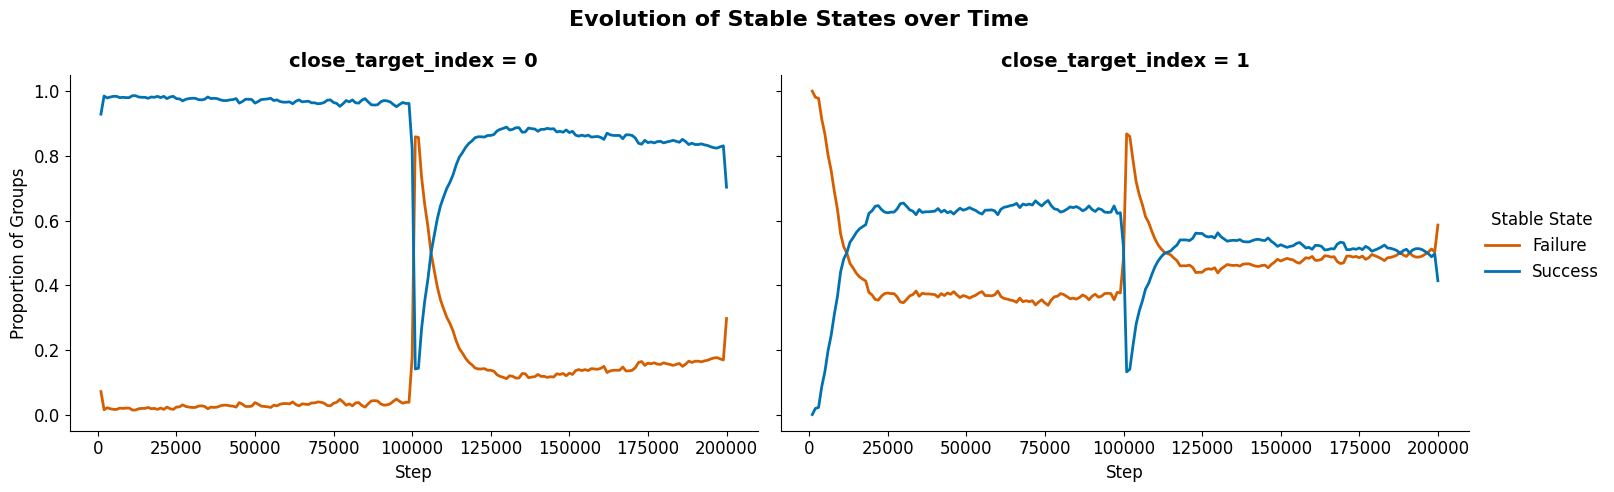

In [81]:
# Extract unique state per group per step
group_states_time = df_flow_all[['run_id', 'group_id', 'step', 'close_target_index', 'stable_state']].drop_duplicates()

# Calculate proportion of groups in each state per step, per close_target_index
state_props = group_states_time.groupby(['step', 'close_target_index', 'stable_state']).size().unstack(fill_value=0)
state_props = state_props.div(state_props.sum(axis=1), axis=0).reset_index()

# Reshape for seaborn
state_props_melted = state_props.melt(id_vars=['step', 'close_target_index'], value_name='proportion', var_name='state')

# Plot
g = sns.FacetGrid(state_props_melted, col='close_target_index', hue='state', height=5, aspect=1.5, 
                  palette={'Success': '#0072B2', 'Failure': '#D55E00', 'Mix': '#CC79A7'})
g.map(sns.lineplot, 'step', 'proportion', linewidth=2)
g.add_legend(title='Stable State')
g.set_axis_labels("Step", "Proportion of Groups")

for ax, title in zip(g.axes.flat, g.col_names):
    ax.set_title(f"close_target_index = {title}", fontsize=14, weight='bold')

plt.subplots_adjust(top=0.85)
g.fig.suptitle("Evolution of Stable States over Time", fontsize=16, weight='bold')
plt.savefig('state_evolution_over_time.png', dpi=300)
plt.show()

### Individual Group Trajectories
We visualize the exact state trajectory (Success, Failure, Mix) of every individual group over time, sorted by the total time they spend in the Success state during the first 100k steps. We also embed flow diagrams for key regions of interest.

In [69]:
import matplotlib.colors as mcolors
from matplotlib.patches import Polygon, Rectangle
from scipy.stats import binned_statistic_2d
from scipy.ndimage import gaussian_filter
import numpy.ma as ma
from sklearn.cluster import KMeans
import matplotlib.transforms as mtransforms

def draw_density_heatmap(ax, data, cmap, title, H=np.sqrt(3)/2):
    triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=3.5, zorder=4)
    ax.add_patch(triangle)

    grid_res = 50
    x_bins = np.linspace(-0.05, 1.05, grid_res)
    y_bins = np.linspace(-0.05, H + 0.05, grid_res)

    if len(data) >= 5:
        Counts, _, _, _ = binned_statistic_2d(data['mx'], data['my'], data['mx'], statistic='count', bins=[x_bins, y_bins])
        Counts = Counts.T

        density = gaussian_filter(Counts, sigma=1.5)
        if density.max() > 0:
            density = density / density.max()

        density_masked = ma.masked_where(density < 0.05, density)

        X, Y = np.meshgrid(x_bins, y_bins)
        colormesh = ax.pcolormesh(X, Y, density_masked, cmap=cmap, shading='flat', zorder=2, alpha=0.95, rasterized=True)

        clip_poly = Polygon([[0, 0], [1, 0], [0.5, H]], transform=ax.transData)
        colormesh.set_clip_path(clip_poly)

    ax.text(0.5, H + 0.02, "S", ha='center', va='bottom', fontsize=24, weight='bold')
    ax.text(-0.02, -0.02, "P", ha='right', va='top', fontsize=24, weight='bold')
    ax.text(1.02, -0.02, "N", ha='left', va='top', fontsize=24, weight='bold')

    if 'gene_eve' in data.columns and len(data) > 0:
        mean_eve = data['gene_eve'].mean()
        ax.text(0.5, -0.15, f"Eve: {mean_eve:.2f}", ha='center', va='top', fontsize=20, weight='bold')

    ax.axis('off')
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=24, weight='bold', pad=25)

state_map = {'Success': 2, 'Failure': 0, 'Mix': 1}
cmap = mcolors.ListedColormap(['#D55E00', '#CC79A7', '#0072B2'])

if 'mx' not in df_gs_all.columns:
    H = np.sqrt(3)/2
    df_gs_all['mx'] = df_gs_all['prob_none'] + 0.5 * df_gs_all['prob_soc']
    df_gs_all['my'] = H * df_gs_all['prob_soc']

conditions = sorted(group_states_time['close_target_index'].unique())

for i, cond in enumerate(conditions):
    cond_data = group_states_time[group_states_time['close_target_index'] == cond].copy()
    cond_data['unique_group'] = cond_data['run_id'].astype(str) + '_' + cond_data['group_id'].astype(str)
    heatmap_data = cond_data.pivot(index='unique_group', columns='step', values='stable_state')
    heatmap_int = heatmap_data.replace(state_map).infer_objects(copy=False)

    X_cluster = heatmap_int.fillna(1).values
    kmeans = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_cluster)
    cluster_labels = kmeans.labels_

    group_success = (heatmap_data == 'Success').sum(axis=1).values
    cluster_avg_success = {c: group_success[cluster_labels == c].mean() for c in range(4)}
    sorted_clusters = sorted(cluster_avg_success.keys(), key=lambda c: cluster_avg_success[c])

    sorted_indices = []
    for c in sorted_clusters:
        idx_in_cluster = np.where(cluster_labels == c)[0]
        sorted_idx_in_cluster = idx_in_cluster[np.argsort(group_success[idx_in_cluster])]
        sorted_indices.extend(sorted_idx_in_cluster)

    heatmap_data = heatmap_data.iloc[sorted_indices]
    heatmap_int = heatmap_int.iloc[sorted_indices]
    heatmap_int_cols = heatmap_int.columns
    heatmap_int.columns = heatmap_int.columns / 1000

    import numpy as np
    fig = plt.figure(figsize=(38, 20))
    ax_main = fig.add_axes([0.15, 0.35, 0.58, 0.30])

    extent = [heatmap_int.columns.min(), heatmap_int.columns.max(), 0, heatmap_data.shape[0]]
    cax = ax_main.imshow(heatmap_int, aspect='auto', cmap=cmap, interpolation='none', vmin=-0.5, vmax=2.5, extent=extent, origin='lower')

    ax_main.set_xlabel("Generation (1k steps)", fontsize=32, labelpad=15)
    # Update x-ticks to be every 25
    custom_ticks = [1] + list(np.arange(25, 200, 25)) + [200]
    
    ax_main.set_xticks(custom_ticks)
    ax_main.set_xticklabels([str(x) for x in custom_ticks])
    ax_main.tick_params(labelsize=24)
    ax_main.axvline(x=105, color='white', linestyle=':', linewidth=3)

    title_str = "Init Good Target" if cond == 0 else "Init Bad Target"
    ax_main.set_yticks([])
    ax_main.set_ylabel(f"{title_str}\n\nIndividual Groups\n(Clustered & Sorted)", fontsize=28, weight='bold', labelpad=40)

    num_groups = heatmap_data.shape[0]
    regions = []

    if cond == 0:
        top_windows = [[5, 15], [75, 85], [105, 115], [190, 200]]
        x_pos = [0.15, 0.32, 0.49, 0.66]
        for idx, gw in enumerate(top_windows):
            regions.append({
                'name': f'Gen {gw[0]}-{gw[1]}', 'gen_x': gw, 'y': [num_groups-100, num_groups], 
                'cmap': 'Blues', 'fig_x': x_pos[idx], 'fig_y': 0.73,
                'groups': heatmap_data.index[num_groups-100:num_groups]
            })

        bot_windows = [[5, 15], [75, 85], [105, 115], [190, 200]]
        for idx, gw in enumerate(bot_windows):
            regions.append({
                'name': f'Gen {gw[0]}-{gw[1]}', 'gen_x': gw, 'y': [0, 25], 
                'cmap': 'Reds', 'fig_x': x_pos[idx], 'fig_y': 0.10,
                'groups': heatmap_data.index[0:25]
            })
    else:
        top_bot_windows = [[1, 5], [5, 10], [10, 15], [75, 85], [105, 115], [190, 200]]
        x_pos_tb = [0.15, 0.25, 0.35, 0.45, 0.55, 0.65]

        for idx, gw in enumerate(top_bot_windows):
            regions.append({
                'name': f'Gen {gw[0]}-{gw[1]}', 'gen_x': gw, 'y': [num_groups-100, num_groups], 
                'cmap': 'Blues', 'fig_x': x_pos_tb[idx], 'fig_y': 0.73,
                'groups': heatmap_data.index[num_groups-100:num_groups]
            })
        for idx, gw in enumerate(top_bot_windows):
            regions.append({
                'name': f'Gen {gw[0]}-{gw[1]}', 'gen_x': gw, 'y': [0, 100], 
                'cmap': 'Reds', 'fig_x': x_pos_tb[idx], 'fig_y': 0.10,
                'groups': heatmap_data.index[0:100]
            })

    steps_fail = [s for s in heatmap_int_cols if 95000 <= s <= 105000]
    steps_succ = [s for s in heatmap_int_cols if 125000 <= s <= 135000]
    fail_mask = heatmap_data[steps_fail].eq('Failure').any(axis=1)
    succ_mask = heatmap_data[steps_succ].eq('Success').any(axis=1)
    recovering = fail_mask & succ_mask
    y_indices = np.where(recovering)[0]

    if len(y_indices) > 0:
        mid_idx = len(y_indices) // 2
        slice_start = max(0, mid_idx)
        slice_end = min(len(y_indices), mid_idx + 40)
        y_indices = y_indices[slice_start:slice_end]

        if len(y_indices) > 0:
            y_min, y_max = y_indices.min(), y_indices.max() + 1
            recov_groups = heatmap_data.index[y_indices]

            mid_windows = [[95, 105], [105, 115], [115, 125], [125, 135]]
            y_pos_right = [0.73, 0.52, 0.31, 0.10] 
            for idx, gw in enumerate(mid_windows):
                regions.append({
                    'name': f'Gen {gw[0]}-{gw[1]}', 'gen_x': gw, 'y': [y_min, y_max], 
                    'cmap': 'Purples', 'fig_x': 0.8, 'fig_y': y_pos_right[idx],
                    'groups': recov_groups
                })

    for r_idx, r in enumerate(regions):
        box_num = r_idx + 1
        rect = Rectangle((r['gen_x'][0], r['y'][0]), r['gen_x'][1]-r['gen_x'][0], r['y'][1]-r['y'][0], 
                         linewidth=4.5, edgecolor='black', facecolor='none', zorder=5)
        ax_main.add_patch(rect)

        x_center = r['gen_x'][0] + (r['gen_x'][1] - r['gen_x'][0]) / 2
        ax_main.text(x_center, r['y'][1], str(box_num),
                     color='black', fontsize=18, weight='bold', ha='center', va='bottom',
                     bbox=dict(facecolor='white', edgecolor='black', boxstyle='circle,pad=0.2', alpha=0.9), zorder=6)

        step_start = r['gen_x'][0] * 1000
        step_end = r['gen_x'][1] * 1000

        mask = (df_gs_all['step'] >= step_start) & (df_gs_all['step'] <= step_end)
        data_subset = df_gs_all[mask].copy()
        if 'unique_group' not in data_subset.columns:
            data_subset['unique_group'] = data_subset['run_id'].astype(str) + '_' + data_subset['group_id'].astype(str)
        data_subset = data_subset[data_subset['unique_group'].isin(r['groups'])]

        axins = fig.add_axes([r['fig_x'], r['fig_y'], 0.08, 0.15])
        title_with_num = f"({box_num}) {r['name']}"
        draw_density_heatmap(axins, data_subset, r['cmap'], title_with_num)

    cbar_ax = fig.add_axes([0.735, 0.35, 0.015, 0.30])
    cbar = fig.colorbar(cax, cax=cbar_ax, orientation='vertical', ticks=[0, 1, 2])
    cbar.ax.set_yticklabels(['Failure', 'Mix', 'Success'], rotation=90, va='center')
    cbar.ax.tick_params(labelsize=28)
    cbar.set_label('State', fontsize=32, weight='bold', labelpad=5)

    filename = 'individual_trajectories_annotated_good.pdf' if cond == 0 else 'individual_trajectories_annotated_bad.pdf'
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close(fig)


### Flow Diagrams within Stable States
We visualize the overall gene flow during the `Success`, `Failure`, and `Mix` periods.

Calculating gradients for stable states...


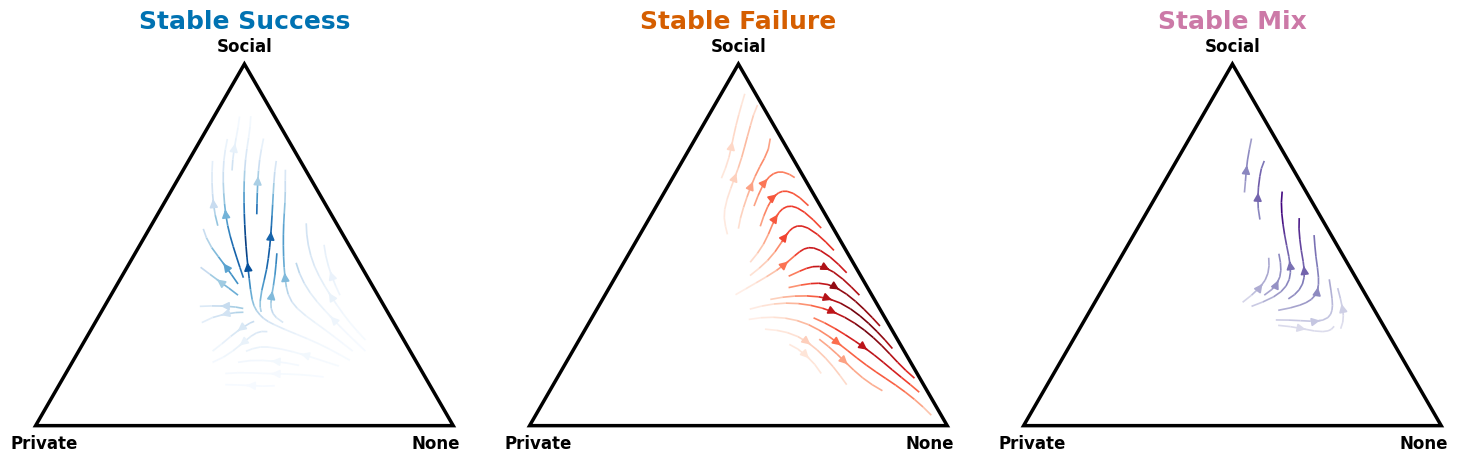

In [18]:
print("Calculating gradients for stable states...")

H = np.sqrt(3) / 2
df_gs_all['mx'] = df_gs_all['prob_none'] + 0.5 * df_gs_all['prob_soc']
df_gs_all['my'] = H * df_gs_all['prob_soc']

df_gs_all = df_gs_all.sort_values(['run_id', 'group_id', 'step'])
df_gs_all['dmx'] = df_gs_all.groupby(['run_id', 'group_id'])['mx'].diff()
df_gs_all['dmy'] = df_gs_all.groupby(['run_id', 'group_id'])['my'].diff()
df_gs_all = df_gs_all.dropna(subset=['dmx', 'dmy'])

states = ['Success', 'Failure', 'Mix']
state_colors = {'Success': 'Blues', 'Failure': 'Reds', 'Mix': 'Purples'}
state_titles = {'Success': '#0072B2', 'Failure': '#D55E00', 'Mix': '#CC79A7'}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
plt.rcParams.update({'font.size': 12})

grid_res = 35
x_bins = np.linspace(-0.05, 1.05, grid_res)
y_bins = np.linspace(-0.05, H + 0.05, grid_res)
X, Y = np.meshgrid(x_bins[:-1] + np.diff(x_bins)/2, y_bins[:-1] + np.diff(y_bins)/2)

for col, state in enumerate(states):
    ax = axes[col]
    state_data = df_gs_all[df_gs_all['stable_state'] == state]

    triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
    ax.add_patch(triangle)

    if len(state_data) >= 50:
        U, _, _, _ = binned_statistic_2d(state_data['mx'], state_data['my'], state_data['dmx'], statistic='mean', bins=[x_bins, y_bins])
        V, _, _, _ = binned_statistic_2d(state_data['mx'], state_data['my'], state_data['dmy'], statistic='mean', bins=[x_bins, y_bins])
        Counts, _, _, _ = binned_statistic_2d(state_data['mx'], state_data['my'], state_data['dmx'], statistic='count', bins=[x_bins, y_bins])

        U, V, Counts = U.T, V.T, Counts.T

        U_smooth = gaussian_filter(np.nan_to_num(U, 0), sigma=1.0)
        V_smooth = gaussian_filter(np.nan_to_num(V, 0), sigma=1.0)

        mask = Counts < 5
        U_masked = ma.array(U_smooth, mask=mask)
        V_masked = ma.array(V_smooth, mask=mask)

        density = gaussian_filter(Counts, sigma=1.5)
        density_masked = ma.array(density, mask=mask)

        try:
            ax.streamplot(X, Y, U_masked, V_masked, color=density_masked, cmap=state_colors[state], 
                          linewidth=1.2, density=1.2, arrowsize=1.2, zorder=2)
        except ValueError:
            pass

    ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=12, weight='bold')
    ax.text(0.1, -0.02, "Private", ha='right', va='top', fontsize=12, weight='bold')
    ax.text(0.9, -0.02, "None", ha='left', va='top', fontsize=12, weight='bold')

    ax.axis('off')
    ax.set_aspect('equal')
    ax.set_title(f"Stable {state}", fontsize=18, weight='bold', color=state_titles[state], pad=15)

plt.tight_layout()
plt.savefig('stable_states_flow.png', dpi=300)
plt.show()


In [19]:
df_gs_all

,run_id,group_id,step,stable_state,prob_priv,prob_soc,prob_none,gene_eve,mx,my,dmx,dmy
1,dment0yi,0.0,1999,Failure,0.318592,0.328289,0.353118,0.029016,0.517263,0.284307,0.064693,0.030602
2,dment0yi,0.0,2999,Failure,0.252156,0.364556,0.383288,0.036759,0.565566,0.315715,0.048303,0.031408
3,dment0yi,0.0,3999,Failure,0.197677,0.405731,0.396592,-0.045542,0.599458,0.351374,0.033892,0.035659
4,dment0yi,0.0,4999,Failure,0.157151,0.436741,0.406108,-0.099339,0.624479,0.378229,0.025021,0.026855
5,dment0yi,0.0,5999,Failure,0.127527,0.469956,0.402517,-0.057911,0.637495,0.406994,0.013016,0.028765
...,...,...,...,...,...,...,...,...,...,...,...,...
399995,lck2wafo,999.0,195999,Success,0.257681,0.582675,0.159643,1.172982,0.450981,0.504612,-0.005273,-0.004957
399996,lck2wafo,999.0,196999,Success,0.252053,0.587635,0.160312,1.167127,0.454129,0.508907,0.003148,0.004295
399997,lck2wafo,999.0,197999,Success,0.254728,0.586568,0.158704,1.162211,0.451988,0.507983,-0.002141,-0.000924
399998,lck2wafo,999.0,198999,Success,0.254948,0.586525,0.158526,1.177409,0.451789,0.507946,-0.000199,-0.000037


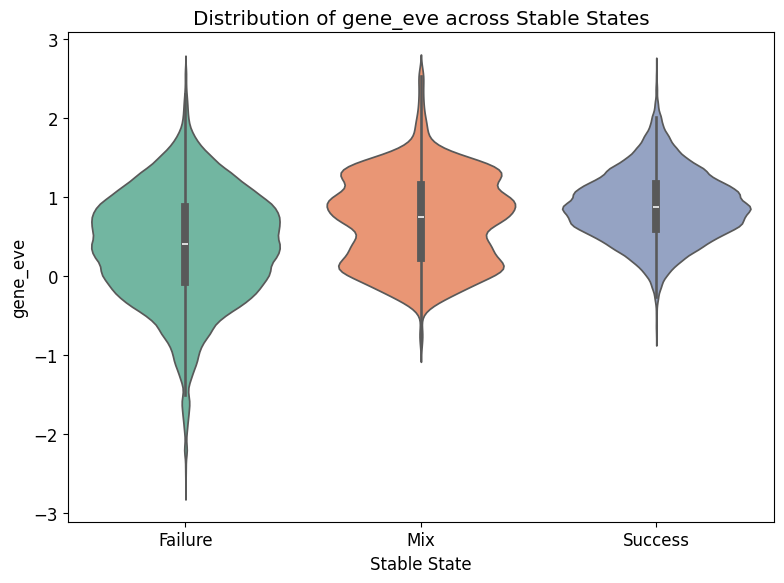

In [22]:
plt.figure(figsize=(8, 6))
sns.violinplot(data=df_gs_all, x='stable_state', hue='stable_state', y='gene_eve', order=['Failure', 'Mix', 'Success'], palette='Set2')
plt.title('Distribution of gene_eve across Stable States')
plt.xlabel('Stable State')
plt.ylabel('gene_eve')
plt.tight_layout()
plt.savefig('gene_eve_distribution.png', dpi=300)
plt.show();

### Flow Diagrams during Transitions
We extract transition events where a `Stable Failure` directly (or via `Mix`) becomes `Stable Success`, and vice versa. We align trajectories to the transition boundary.

In [ ]:
print("Extracting transitions and aligning trajectories...")

transition_data = []

# Identify macro transitions per group
for (run_id, group_id), group_df in df_success.groupby(['run_id', 'group_id']):
    # Compress sequence of states
    group_df = group_df.sort_values('step')

    # We only care when the stable state changes
    state_changes = group_df[group_df['stable_state'] != group_df['stable_state'].shift()]

    # Iterate through changes to find Stable -> Stable transitions
    prev_stable = None
    mix_start = None

    for idx, row in state_changes.iterrows():
        current_state = row['stable_state']
        current_step = row['step']

        if current_state in ['Success', 'Failure']:
            if prev_stable is not None and prev_stable != current_state:
                # We found a transition!
                trans_type = f"{prev_stable} -> {current_state}"

                mix_length = 0 if mix_start is None else (current_step - mix_start)
                t_start = mix_start if mix_start is not None else current_step

                transition_data.append({
                    'run_id': run_id,
                    'group_id': group_id,
                    'trans_type': trans_type,
                    't_start': t_start,
                    'mix_length': mix_length
                })

            # Reset trackers
            prev_stable = current_state
            mix_start = None

        elif current_state == 'Mix':
            # This marks the end of the previous stable state (if any)
            # and the potential start of a Mix bridge
            mix_start = current_step

trans_df = pd.DataFrame(transition_data)
print("Identified Transitions:")
if not trans_df.empty:
    print(trans_df['trans_type'].value_counts())
else:
    print("No transitions found!")

plot_segments = []
step_inc = 1000 # Typical interval in this dataset for 1 step

for _, trans in trans_df.iterrows():
    run = trans['run_id']
    grp = trans['group_id']
    ttype = trans['trans_type']
    t_start = trans['t_start']
    mix_len = trans['mix_length']

    g_data = df_gs_all[(df_gs_all['run_id'] == run) & (df_gs_all['group_id'] == grp)].copy()

    g_data['rel_step'] = g_data['step'] - t_start
    g_data['phase'] = 'None'

    pre_mask = (g_data['rel_step'] >= -10 * step_inc) & (g_data['rel_step'] < 0)
    g_data.loc[pre_mask, 'phase'] = 'Pre Transition'

    during_mask = (g_data['rel_step'] >= 0) & (g_data['rel_step'] < mix_len)
    g_data.loc[during_mask, 'phase'] = 'During (Mix)'

    # If there is no mix length, "During" will be empty, which is accurate.
    # Post mask starts AFTER the mix period ends
    post_mask = (g_data['rel_step'] >= mix_len) & (g_data['rel_step'] < mix_len + 10 * step_inc)
    g_data.loc[post_mask, 'phase'] = 'Post Transition'

    g_data['trans_type'] = ttype
    plot_segments.append(g_data[g_data['phase'] != 'None'])

if plot_segments:
    plot_df = pd.concat(plot_segments)

    trans_types = ['Failure -> Success', 'Success -> Failure']
    phases = ['Pre Transition', 'During (Mix)', 'Post Transition']
    trans_colors = {'Failure -> Success': 'Greens', 'Success -> Failure': 'Reds'}
    trans_titles = {'Failure -> Success': '#009E73', 'Success -> Failure': '#D55E00'}

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    plt.rcParams.update({'font.size': 12})

    for row, ttype in enumerate(trans_types):
        ttype_data = plot_df[plot_df['trans_type'] == ttype]

        for col, phase in enumerate(phases):
            ax = axes[row, col]
            phase_data = ttype_data[ttype_data['phase'] == phase]

            triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
            ax.add_patch(triangle)

            # Use a much lower threshold since these segments are only 10 steps long
            if len(phase_data) >= 5:  
                U, _, _, _ = binned_statistic_2d(phase_data['mx'], phase_data['my'], phase_data['dmx'], statistic='mean', bins=[x_bins, y_bins])
                V, _, _, _ = binned_statistic_2d(phase_data['mx'], phase_data['my'], phase_data['dmy'], statistic='mean', bins=[x_bins, y_bins])
                Counts, _, _, _ = binned_statistic_2d(phase_data['mx'], phase_data['my'], phase_data['dmx'], statistic='count', bins=[x_bins, y_bins])

                U, V, Counts = U.T, V.T, Counts.T

                U_smooth = gaussian_filter(np.nan_to_num(U, 0), sigma=1.0)
                V_smooth = gaussian_filter(np.nan_to_num(V, 0), sigma=1.0)

                mask = Counts < 2
                U_masked = ma.array(U_smooth, mask=mask)
                V_masked = ma.array(V_smooth, mask=mask)

                density = gaussian_filter(Counts, sigma=1.5)
                density_masked = ma.array(density, mask=mask)

                try:
                    ax.streamplot(X, Y, U_masked, V_masked, color=density_masked, cmap=trans_colors[ttype], 
                                  linewidth=1.2, density=1.2, arrowsize=1.2, zorder=2)
                except ValueError:
                    pass

            ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=12, weight='bold')
            ax.text(0.1, -0.02, "Private", ha='right', va='top', fontsize=12, weight='bold')
            ax.text(0.9, -0.02, "None", ha='left', va='top', fontsize=12, weight='bold')

            ax.axis('off')
            ax.set_aspect('equal')

            if row == 0:
                ax.set_title(phase, fontsize=18, weight='bold', pad=15)

        axes[row, 0].text(-0.25, H/2, ttype, rotation=90, va='center', ha='center', 
                          fontsize=22, weight='bold', color=trans_titles[ttype])

    plt.tight_layout()
    plt.savefig('transitions_flow.png', dpi=300)
    plt.show()
else:
    print("Not enough transitions to plot.")


### Clustered Trajectories & Gene Timeseries
We enhance the trajectory visual by drawing bounding boxes around the identified clusters and plotting the average gene timeseries below.

In [86]:

import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
from scipy.ndimage import gaussian_filter1d

# New Visualization: Clustered Trajectories with Gene Timeseries
n_clusters = 6
print("Generating clustered trajectories with gene timeseries...")

for i, cond in enumerate(conditions):
    cond_data = group_states_time[group_states_time['close_target_index'] == cond].copy()
    cond_data['unique_group'] = cond_data['run_id'].astype(str) + '_' + cond_data['group_id'].astype(str)
    heatmap_data = cond_data.pivot(index='unique_group', columns='step', values='stable_state')
    heatmap_int = heatmap_data.replace(state_map).infer_objects(copy=False)

    X_cluster = heatmap_int.fillna(1).values
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10).fit(X_cluster)
    cluster_labels = kmeans.labels_

    group_success = (heatmap_data == 'Success').sum(axis=1).values
    cluster_avg_success = {c: group_success[cluster_labels == c].mean() for c in range(n_clusters)}
    sorted_clusters = sorted(cluster_avg_success.keys(), key=lambda c: cluster_avg_success[c])

    sorted_indices = []
    cluster_boundaries = []
    current_y = 0
    
    # Track the groups belonging to each sorted cluster
    cluster_groups = []
    
    for c in sorted_clusters:
        idx_in_cluster = np.where(cluster_labels == c)[0]
        sorted_idx_in_cluster = idx_in_cluster[np.argsort(group_success[idx_in_cluster])]
        sorted_indices.extend(sorted_idx_in_cluster)
        
        size = len(idx_in_cluster)
        cluster_boundaries.append((current_y, current_y + size))
        current_y += size
        
        # Keep track of unique group IDs for this cluster
        groups = heatmap_data.index[sorted_idx_in_cluster].tolist()
        cluster_groups.append(groups)

    heatmap_data = heatmap_data.iloc[sorted_indices]
    heatmap_int = heatmap_int.iloc[sorted_indices]
    heatmap_int_cols = heatmap_int.columns
    heatmap_int.columns = heatmap_int.columns / 1000

    # Create figure with GridSpec: top for heatmap, middle for info genes, bottom for process noise
    fig = plt.figure(figsize=(38, 32))
    gs = gridspec.GridSpec(3, n_clusters, height_ratios=[2, 1, 1], hspace=0.18, wspace=0.05)
    
    ax_main = fig.add_subplot(gs[0, :])

    extent = [heatmap_int.columns.min(), heatmap_int.columns.max(), 0, heatmap_data.shape[0]]
    cax = ax_main.imshow(heatmap_int, aspect='auto', cmap=cmap, interpolation='none', vmin=-0.5, vmax=2.5, extent=extent, origin='lower')

    ax_main.set_xlabel("Generation (1k steps)", fontsize=32, labelpad=0)
    custom_ticks = [1] + list(np.arange(25, 200, 25)) + [200]
    ax_main.set_xticks(custom_ticks)
    ax_main.set_xticklabels([str(x) for x in custom_ticks])
    ax_main.tick_params(labelsize=24)
    ax_main.axvline(x=100, color='white', linestyle=':', linewidth=3)

    title_str = "Init on Good Target" if cond == 0 else "Init on Bad Target"
    ax_main.set_yticks([])
    ax_main.set_ylabel(f"Groups {title_str} (Clustered & Sorted)", fontsize=28, weight='bold', labelpad=70)

    # Highlight clusters with black bounding boxes and numbered labels outside to the left
    for idx, (y_min, y_max) in enumerate(cluster_boundaries):
        rect = Rectangle((extent[0], y_min), extent[1]-extent[0], y_max-y_min, 
                         linewidth=6, edgecolor='black', facecolor='none', zorder=5)
        ax_main.add_patch(rect)
        
        # Label the cluster outside on the left side (avoid overlapping with y label)
        # Note: idx=0 is worst, idx=3 is best. We label best as 1, worst as 4.
        ax_main.text(extent[0] - 1, (y_min + y_max)/2, f'{n_clusters-idx}', 
                     color='black', fontsize=36, weight='bold', va='center', ha='right',
                     bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))

    # Add colorbar for main heatmap
    cbar_ax = fig.add_axes([0.91, 0.53, 0.015, 0.35])
    cbar = fig.colorbar(cax, cax=cbar_ax, orientation='vertical', ticks=[0, 1, 2])
    cbar.ax.set_yticklabels(['Failure', 'Mix', 'Success'], rotation=90, va='center')
    cbar.ax.tick_params(labelsize=28)
    cbar.set_label('State', fontsize=32, weight='bold', labelpad=5)

    # Info genes settings (Colorblind friendly)
    info_genes = ['prob_priv', 'prob_soc', 'prob_none']
    info_labels = ['Private', 'Social', 'None']
    info_colors = ['#0072B2', '#E69F00', '#009E73'] 
    
    # Process noise settings
    # Scale gene_eve from logits to actual process noise bounds [0.01, 0.1]
    import numpy as np
    df_gs_all['gene_eve_scaled'] = (1 / (1 + np.exp(-df_gs_all['gene_eve']))) * (0.1 - 0.01) + 0.01
    noise_gene = 'gene_eve_scaled'
    noise_label = 'Process Noise'
    noise_color = '#CC79A7' 
    
    # Ensure df_gs_all has a unique_group column
    if 'unique_group' not in df_gs_all.columns:
        df_gs_all['unique_group'] = df_gs_all['run_id'].astype(str) + '_' + df_gs_all['group_id'].astype(str)
        
    for cluster_col, (cluster_idx, groups) in enumerate(reversed(list(enumerate(cluster_groups)))):
        ax_info = fig.add_subplot(gs[1, cluster_col])
        ax_noise = fig.add_subplot(gs[2, cluster_col])
        
        cluster_df = df_gs_all[df_gs_all['unique_group'].isin(groups)]
        
        # 1. Info genes (Row 1)
        for gene_idx, gene_name in enumerate(info_genes):
            color = info_colors[gene_idx]
            step_agg = cluster_df.groupby('step')[gene_name].agg(['mean', 'std']).reset_index()
            x_vals = (step_agg['step'] + 1) / 1000
            y_mean = step_agg['mean'].values
            y_std = step_agg['std'].values
            
            # No smoothing, with uncertainty bands
            ax_info.plot(x_vals, y_mean, color=color, linewidth=2, label=info_labels[gene_idx])
            import numpy as np
            ax_info.fill_between(x_vals, np.clip(y_mean - y_std, 0, 1), np.clip(y_mean + y_std, 0, 1), color=color, alpha=0.2)
            
        ax_info.set_title(f'Cluster {cluster_col+1}', fontsize=28, weight='bold', color='black')
        ax_info.set_ylim(0, 0.85)
        ax_info.tick_params(labelsize=18)
        ax_info.set_xticks([1] + list(np.arange(50, 250, 50)))
        ax_info.set_xticklabels([]) # Hide x labels for the middle row
        ax_info.axvline(x=100, color='gray', linestyle=':', linewidth=2)
        ax_info.grid(True, linestyle='--', alpha=0.5)
        
        if cluster_col == 0:
            ax_info.set_ylabel("Probabilities", fontsize=22)
            ax_info.legend(fontsize=20, loc='best')
        else:
            ax_info.set_yticklabels([])
            
        # 2. Process Noise (Row 2)
        step_agg = cluster_df.groupby('step')[noise_gene].agg(['mean', 'std']).reset_index()
        x_vals = (step_agg['step'] + 1) / 1000
        y_mean = step_agg['mean'].values
        y_std = step_agg['std'].values
        
        ax_noise.plot(x_vals, y_mean, color=noise_color, linewidth=2, label=noise_label)
        ax_noise.fill_between(x_vals, np.clip(y_mean - y_std, 0.04, 0.09), np.clip(y_mean + y_std, 0.04, 0.09), color=noise_color, alpha=0.2)
        
        ax_noise.set_ylim(0.04, 0.09)
        ax_noise.set_xlabel("Generation (1k steps)", fontsize=22)
        ax_noise.tick_params(labelsize=18)
        ax_noise.set_xticks([1] + list(np.arange(50, 250, 50)))
        ax_noise.axvline(x=100, color='gray', linestyle=':', linewidth=2)
        ax_noise.grid(True, linestyle='--', alpha=0.5)
        
        if cluster_col == 0:
            ax_noise.set_ylabel("Process Noise", fontsize=22)
        else:
            ax_noise.set_yticklabels([])

    filename = 'clustered_trajectories_gene_ts_good.pdf' if cond == 0 else 'clustered_trajectories_gene_ts_bad.pdf'
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close(fig)



Generating clustered trajectories with gene timeseries...


### Clustered Trajectories & Gene Timeseries (Raw Median Performance)
We enhance the trajectory visual by drawing bounding boxes around the identified clusters and plotting the average gene timeseries below. Here we use the raw median performance per group instead of discrete states.

In [131]:

print("Calculating raw median performance per group from df...")
group_perf = df.groupby(['run_id', 'group_id', 'step', 'close_target_index'])['current_fitness'].median().reset_index()
group_perf = group_perf[group_perf['step'] < 199000]
group_perf['unique_group'] = group_perf['run_id'].astype(str) + '_' + group_perf['group_id'].astype(str)

import matplotlib.gridspec as gridspec
from matplotlib.patches import Polygon, Rectangle
from scipy.stats import binned_statistic_2d
from scipy.ndimage import gaussian_filter1d, gaussian_filter
import numpy.ma as ma
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors
import seaborn as sns

def draw_streamplot(ax, data, cmap, title, H=np.sqrt(3)/2):
    triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
    ax.add_patch(triangle)

    grid_res = 50
    x_bins = np.linspace(-0.05, 1.05, grid_res)
    y_bins = np.linspace(-0.05, H + 0.05, grid_res)
    
    X, Y = np.meshgrid(x_bins[:-1] + np.diff(x_bins)/2, y_bins[:-1] + np.diff(y_bins)/2)
    
    if len(data) >= 5 and 'dmx' in data.columns:
        U, _, _, _ = binned_statistic_2d(data['mx'], data['my'], data['dmx'], statistic='mean', bins=[x_bins, y_bins])
        V, _, _, _ = binned_statistic_2d(data['mx'], data['my'], data['dmy'], statistic='mean', bins=[x_bins, y_bins])
        Counts, _, _, _ = binned_statistic_2d(data['mx'], data['my'], data['dmx'], statistic='count', bins=[x_bins, y_bins])

        U, V, Counts = U.T, V.T, Counts.T

        U_smooth = gaussian_filter(np.nan_to_num(U, 0), sigma=1.0)
        V_smooth = gaussian_filter(np.nan_to_num(V, 0), sigma=1.0)

        mask = Counts < 2
        U_masked = ma.array(U_smooth, mask=mask)
        V_masked = ma.array(V_smooth, mask=mask)

        density = gaussian_filter(Counts, sigma=1.5)
        density_masked = ma.array(density, mask=mask)

        try:
            ax.streamplot(X, Y, U_masked, V_masked, color=density_masked, cmap=cmap, 
                          linewidth=1.2, density=1.2, arrowsize=1.2, zorder=2)
        except ValueError:
            pass

    ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=16, weight='bold')
    ax.text(0.1, -0.02, "Private", ha='right', va='top', fontsize=16, weight='bold')
    ax.text(0.9, -0.02, "None", ha='left', va='top', fontsize=16, weight='bold')

    ax.axis('off')
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=24, weight='bold', pad=25)

n_clusters = 6
palette = sns.color_palette("coolwarm_r", as_cmap=True)
custom_cmap = mcolors.ListedColormap(['#E69F00', '#0072B2'])
# Define the threshold at 0.7 (bounds encompass potential min and max values)
bounds = [-0.1, 0.6, 1] 
norm = mcolors.BoundaryNorm(bounds, custom_cmap.N)
print("Generating clustered trajectories based on raw median performance...")

conditions = sorted(group_perf['close_target_index'].unique())

for i, cond in enumerate(conditions):
    cond_data = group_perf[group_perf['close_target_index'] == cond].copy()
    
    heatmap_data = cond_data.pivot(index='unique_group', columns='step', values='current_fitness')
    
    X_cluster = heatmap_data.fillna(0).values
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10).fit(X_cluster)
    cluster_labels = kmeans.labels_

    group_mean_perf = heatmap_data.mean(axis=1).values
    cluster_avg_perf = {c: group_mean_perf[cluster_labels == c].mean() for c in range(n_clusters)}
    sorted_clusters = sorted(cluster_avg_perf.keys(), key=lambda c: cluster_avg_perf[c])

    sorted_indices = []
    cluster_boundaries = []
    current_y = 0
    
    cluster_groups = []
    
    for c in sorted_clusters:
        idx_in_cluster = np.where(cluster_labels == c)[0]
        sorted_idx_in_cluster = idx_in_cluster[np.argsort(group_mean_perf[idx_in_cluster])]
        sorted_indices.extend(sorted_idx_in_cluster)
        
        size = len(idx_in_cluster)
        cluster_boundaries.append((current_y, current_y + size))
        current_y += size
        
        groups = heatmap_data.index[sorted_idx_in_cluster].tolist()
        cluster_groups.append(groups)

    heatmap_data = heatmap_data.iloc[sorted_indices]
    heatmap_cols = heatmap_data.columns
    
    fig = plt.figure(figsize=(38, 32))
    gs = gridspec.GridSpec(3, n_clusters, height_ratios=[2, 1, 1], hspace=0.18, wspace=0.05)
    
    ax_main = fig.add_subplot(gs[0, :])

    extent = [heatmap_cols.min()/1000, heatmap_cols.max()/1000, 0, heatmap_data.shape[0]]
    
    cax = ax_main.imshow(
        heatmap_data, 
        aspect='auto', 
        cmap=custom_cmap, 
        interpolation='none', 
        extent=extent, 
        norm=norm,
        origin='lower', 
        )

    ax_main.set_xlabel("Generation (1k steps)", fontsize=32, labelpad=0)
    # custom_ticks now stops before 200
    custom_ticks = [1] + list(np.arange(25, 200, 25))
    ax_main.set_xticks(custom_ticks)
    ax_main.set_xticklabels([str(x) for x in custom_ticks])
    ax_main.tick_params(labelsize=24)
    ax_main.axvline(x=100, color='white', linestyle=':', linewidth=3)

    title_str = "Init Good Target" if cond == 0 else "Init Bad Target"
    ax_main.set_yticks([])
    ax_main.set_ylabel(f"Groups {title_str} (Clustered & Sorted)", fontsize=28, weight='bold', labelpad=70)

    for idx, (y_min, y_max) in enumerate(cluster_boundaries):
        rect = Rectangle((extent[0], y_min), extent[1]-extent[0], y_max-y_min, 
                         linewidth=6, edgecolor='black', facecolor='none', zorder=5)
        ax_main.add_patch(rect)
        
        ax_main.text(extent[0] - 2, (y_min + y_max)/2, f'{n_clusters-idx}', 
                     color='black', fontsize=36, weight='bold', va='center', ha='right',
                     bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))

    cbar_ax = fig.add_axes([0.91, 0.53, 0.015, 0.35])
    
    cbar = fig.colorbar(cax, cax=cbar_ax, orientation='vertical', spacing='proportional')
    cbar.ax.tick_params(labelsize=28)
    cbar.set_ticks([0.3, 0.8])
    cbar.ax.set_yticklabels(['< 0.6', '> 0.6'], rotation=90, va='center')
    cbar.ax.tick_params(labelsize=28, length=0)
    cbar.set_label('Median Performance', fontsize=32, weight='bold', labelpad=5)

    info_genes = ['prob_priv', 'prob_soc', 'prob_none']
    info_labels = ['Private', 'Social', 'None']
    info_colors = ['#0072B2', '#E69F00', '#009E73'] 
    
    if 'gene_eve_scaled' not in df_gs_all.columns:
        df_gs_all['gene_eve_scaled'] = (1 / (1 + np.exp(-df_gs_all['gene_eve']))) * (0.1 - 0.01) + 0.01
    noise_gene = 'gene_eve_scaled'
    noise_label = 'Process Noise'
    noise_color = '#CC79A7' 
    
    if 'unique_group' not in df_gs_all.columns:
        df_gs_all['unique_group'] = df_gs_all['run_id'].astype(str) + '_' + df_gs_all['group_id'].astype(str)
        
    for cluster_col, (cluster_idx, groups) in enumerate(reversed(list(enumerate(cluster_groups)))):
        ax_info = fig.add_subplot(gs[1, cluster_col])
        ax_noise = fig.add_subplot(gs[2, cluster_col])
        # ax_flow = fig.add_subplot(gs[3, cluster_col])
        
        cluster_df = df_gs_all[df_gs_all['unique_group'].isin(groups)]
        
        for gene_idx, gene_name in enumerate(info_genes):
            color = info_colors[gene_idx]
            step_agg = cluster_df.groupby('step')[gene_name].agg(['mean', 'std']).reset_index()
            x_vals = (step_agg['step'] + 1) / 1000
            y_mean = step_agg['mean'].values
            y_std = step_agg['std'].values
            
            ax_info.plot(x_vals, y_mean, color=color, linewidth=2, label=info_labels[gene_idx])
            ax_info.fill_between(x_vals, np.clip(y_mean - y_std, 0, 1), np.clip(y_mean + y_std, 0, 1), color=color, alpha=0.2)
            
        ax_info.set_title(f'Cluster {cluster_col+1}', fontsize=28, weight='bold', color='black')
        ax_info.set_ylim(-0.05, 1.05)
        ax_info.tick_params(labelsize=18)
        ax_info.set_xticks([1] + list(np.arange(50, 250, 50)))
        ax_info.set_xticklabels([])
        ax_info.axvline(x=100, color='gray', linestyle=':', linewidth=2)
        ax_info.grid(True, linestyle='--', alpha=0.5)
        
        if cluster_col == 0:
            ax_info.set_ylabel("Probabilities", fontsize=22)
            ax_info.legend(fontsize=20, loc='best')
        else:
            ax_info.set_yticklabels([])
            
        step_agg = cluster_df.groupby('step')[noise_gene].agg(['mean', 'std']).reset_index()
        if not step_agg.empty:
            x_vals = (step_agg['step'] + 1) / 1000
            y_mean = step_agg['mean'].values
            y_std = step_agg['std'].values
            
            ax_noise.plot(x_vals, y_mean, color=noise_color, linewidth=2, label=noise_label)
            ax_noise.fill_between(x_vals, np.clip(y_mean - y_std, 0.04, 0.09), np.clip(y_mean + y_std, 0.04, 0.09), color=noise_color, alpha=0.2)
        
        ax_noise.set_ylim(0.04, 0.09)
        ax_noise.set_xlabel("Generation (1k steps)", fontsize=22)
        ax_noise.tick_params(labelsize=18)
        ax_noise.set_xticks([1] + list(np.arange(50, 250, 50)))
        ax_noise.axvline(x=100, color='gray', linestyle=':', linewidth=2)
        ax_noise.grid(True, linestyle='--', alpha=0.5)
        
        if cluster_col == 0:
            ax_noise.set_ylabel("Process Noise", fontsize=22)
        else:
            ax_noise.set_yticklabels([])

        # Flow Diagrams (Row 4)
        # flow_df = cluster_df[cluster_df['step'] < 7000].copy()
        # if len(flow_df) > 0:
        #     if 'mx' not in flow_df.columns:
        #         H = np.sqrt(3)/2
        #         flow_df['mx'] = flow_df['prob_none'] + 0.5 * flow_df['prob_soc']
        #         flow_df['my'] = H * flow_df['prob_soc']
        #     
        #     flow_df = flow_df.sort_values(['run_id', 'group_id', 'step'])
        #     flow_df['dmx'] = flow_df.groupby(['run_id', 'group_id'])['mx'].diff()
        #     flow_df['dmy'] = flow_df.groupby(['run_id', 'group_id'])['my'].diff()
        #     flow_df = flow_df.dropna(subset=['dmx', 'dmy'])
        #     
        # draw_streamplot(ax_flow, flow_df, 'Blues', 'Flow Gen 1-7')

    filename = 'clustered_trajectories_gene_ts_perf_good.pdf' if cond == 0 else 'clustered_trajectories_gene_ts_perf_bad.pdf'
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    # plt.show()
    plt.close(fig)


Calculating raw median performance per group from df...
Generating clustered trajectories based on raw median performance...


In [132]:
# Separate Flow Diagram for Bad Target Initialization (Clusters 1 and 6)
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from scipy.stats import binned_statistic_2d
from scipy.ndimage import gaussian_filter
from sklearn.svm import LinearSVC
import numpy.ma as ma
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

print("Inferring Divergence Generation and Separatrix...")

if 'mx' not in df_gs_all.columns:
    H = np.sqrt(3)/2
    df_gs_all['mx'] = df_gs_all['prob_none'] + 0.5 * df_gs_all['prob_soc']
    df_gs_all['my'] = H * df_gs_all['prob_soc']

# Identify Best and Worst Groups
best_groups = cluster_groups[5]
worst_groups = cluster_groups[0]

best_df = df_gs_all[df_gs_all['unique_group'].isin(best_groups)]
worst_df = df_gs_all[df_gs_all['unique_group'].isin(worst_groups)]

# Calculate Divergence Step
best_means = best_df.groupby('step')[['mx', 'my']].mean()
worst_means = worst_df.groupby('step')[['mx', 'my']].mean()
merged_means = best_means.join(worst_means, lsuffix='_best', rsuffix='_worst').dropna()
merged_means['dist'] = np.sqrt((merged_means['mx_best'] - merged_means['mx_worst'])**2 + (merged_means['my_best'] - merged_means['my_worst'])**2)

diverge_step = merged_means[merged_means['dist'] > 0.05].index.min()
diverge_gen = (diverge_step + 1) / 1000 if diverge_step is not pd.NA else 6.0
print(f"Divergence Generation: {diverge_gen}")

# Infer Separatrix using SVM
post_best = best_df[best_df['step'] >= diverge_step][['mx', 'my']].dropna()
post_worst = worst_df[worst_df['step'] >= diverge_step][['mx', 'my']].dropna()
X_svm = np.vstack([post_best.values, post_worst.values])
y_svm = np.array([1]*len(post_best) + [0]*len(post_worst))

svm = LinearSVC(random_state=42, C=1.0)
svm.fit(X_svm, y_svm)
w = svm.coef_[0]
b = svm.intercept_[0]
print(f"Separatrix equation: {w[0]:.4f} * mx + {w[1]:.4f} * my + {b:.4f} = 0")

target_clusters = [
    ("Cluster 1 (Best)", best_groups, 'Blues'),
    ("Cluster 6 (Worst)", worst_groups, 'Reds')
]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
H = np.sqrt(3)/2

periods = [
    (f'Gen 0-{int(diverge_gen)} (Pre-Divergence)', lambda d: d['step'] < diverge_step),
    (f'Gen {int(diverge_gen)}-100 (Post-Divergence)', lambda d: d['step'] >= diverge_step)
]

grid_res = 50
x_bins = np.linspace(-0.05, 1.05, grid_res)
y_bins = np.linspace(-0.05, H + 0.05, grid_res)
X, Y = np.meshgrid(x_bins[:-1] + np.diff(x_bins)/2, y_bins[:-1] + np.diff(y_bins)/2)

sep_x = np.linspace(0, 1, 500)
sep_y = -(w[0] * sep_x + b) / (w[1] + 1e-10)

# Mask separatrix to triangle bounds
mask_triangle = (sep_y >= 0) & (sep_y <= np.sqrt(3) * sep_x) & (sep_y <= -np.sqrt(3) * (sep_x - 1))
sep_x = sep_x[mask_triangle]
sep_y = sep_y[mask_triangle]

for row, (cluster_title, groups, cmap) in enumerate(target_clusters):
    cluster_df = df_gs_all[df_gs_all['unique_group'].isin(groups)].copy()
    
    cluster_df = cluster_df.sort_values(['run_id', 'group_id', 'step'])
    cluster_df['dmx'] = cluster_df.groupby(['run_id', 'group_id'])['mx'].diff()
    cluster_df['dmy'] = cluster_df.groupby(['run_id', 'group_id'])['my'].diff()
    
    for col, (period_title, filter_func) in enumerate(periods):
        ax = axes[row, col]
        
        triangle = Polygon([[0, 0], [1, 0], [0.5, H]], fill=False, edgecolor='black', linewidth=2.5, zorder=4)
        ax.add_patch(triangle)
        
        phase_data = cluster_df[filter_func(cluster_df)].dropna(subset=['dmx', 'dmy'])
        
        if len(phase_data) >= 5:
            U, _, _, _ = binned_statistic_2d(phase_data['mx'], phase_data['my'], phase_data['dmx'], statistic='mean', bins=[x_bins, y_bins])
            V, _, _, _ = binned_statistic_2d(phase_data['mx'], phase_data['my'], phase_data['dmy'], statistic='mean', bins=[x_bins, y_bins])
            Counts, _, _, _ = binned_statistic_2d(phase_data['mx'], phase_data['my'], phase_data['dmx'], statistic='count', bins=[x_bins, y_bins])

            U, V, Counts = U.T, V.T, Counts.T

            U_smooth = gaussian_filter(np.nan_to_num(U, 0), sigma=1.0)
            V_smooth = gaussian_filter(np.nan_to_num(V, 0), sigma=1.0)

            mask = Counts < 2
            U_masked = ma.array(U_smooth, mask=mask)
            V_masked = ma.array(V_smooth, mask=mask)

            density = gaussian_filter(Counts, sigma=1.5)
            density_masked = ma.array(density, mask=mask)

            try:
                ax.streamplot(X, Y, U_masked, V_masked, color=density_masked, cmap=cmap, 
                              linewidth=1.5, density=2.5, arrowsize=1.5, zorder=2)
            except ValueError:
                pass
                
        # Draw Separatrix
        ax.plot(sep_x, sep_y, color='black', linestyle='--', linewidth=2.5, zorder=5, label='Inferred Separatrix' if col == 1 else "")
                
        ax.text(0.5, H + 0.02, "Social", ha='center', va='bottom', fontsize=14, weight='bold')
        ax.text(0.1, -0.02, "Private", ha='right', va='top', fontsize=14, weight='bold')
        ax.text(0.9, -0.02, "None", ha='left', va='top', fontsize=14, weight='bold')
        
        ax.axis('off')
        ax.set_aspect('equal')
        
        if row == 0:
            ax.set_title(period_title, fontsize=20, weight='bold', pad=15)
            
        if col == 0:
            ax.text(-0.2, H/2, cluster_title, va='center', ha='right', rotation=90, fontsize=20, weight='bold')
            
        if col == 1 and row == 0:
            ax.legend(loc='upper right', fontsize=12)

plt.tight_layout()
plt.subplots_adjust(top=0.9, left=0.15, wspace=0.1, hspace=0.1)
plt.suptitle("Flow Diagrams (Bad Target Initialization)", fontsize=24, weight='bold')
plt.savefig('flow_clusters_1_6_bad_target.pdf', dpi=300, bbox_inches='tight')
# plt.show()
plt.close(fig)

Inferring Divergence Generation and Separatrix...
Divergence Generation: 6.0
Separatrix equation: -20.1955 * mx + -8.4557 * my + 16.6615 = 0
